# The WTI Volatility Smile under a Quadratic Normal Model

*Can one three-parameter local-volatility parabola price every strike of a WTI option expiry, and what does it change for digital prices and delta hedging?*

---

### Key results

| Question | Result |
|---|---|
| Is the closed-form price accurate? | Against a finite-difference solution: within 1.8¢ for 3-month strikes 60–100 and within 3.5¢ at every 1-year strike. The far 3-month wings (strikes 40 and 120) are under-priced by 23¢, about 60% of their value. |
| Does it fit the market smile? | `m3` in-sample RMSE is 4.2¢, against 33.1¢ for Black and 58.5¢ for Bachelier, with errors flat across strikes. In 2023–2025 the fit is 1.2–1.5¢; the 2026 spike raises it to 8.7¢. |
| Normal or lognormal base? | Normal. Bachelier beats Black every year from 2023 to 2025 (RMSE ratio 0.65–0.91). Only the 2026 call-skew spike reverses the ranking (2.04). |
| How fast do the parameters go stale? | One day later, 18.2¢ (still less than half of the alternatives). Five days later, 46.0¢ against 70.0¢ and 95.2¢. Daily recalibration is required. |
| Are the parameters interpretable? | Yes, when read at the money. The slope sits near zero in 2023–2025 and holds at 0.6–1.8 through the 2026 call skew; curvature falls from 0.04–0.08 to about 0.015 as the smile turns linear. The vertex form `(A, F0)` swings to extremes in the same episode. |
| Is the digital price informative? | The ATM digital ranges from 0.35 to 0.54 with the smile, against a fixed 0.50 (Bachelier). As a forecast of finishing in the money it scores no better than 0.50. |
| Does it hedge better? | Not in normal markets. In 2023–2025 the QNM-to-Black replication-error ratio is 0.98 (90% interval 0.94–1.04). The overall 6–21% lower error (by instrument) comes from five 2026 expiries, where over-hedging the tails pays in a trend, and most of those intervals include 1. |

**Use.** Daily calibration of `m2–m4` WTI smiles, consistent pricing across strikes, and relative value on strikes whose quotes sit away from the fitted curve. It is a pricing model, not a forecaster or a better hedge.

### Model in one line
Futures follow `dF = σ(F) dz` with a parabolic local volatility `σ(F) = σ_A + a + bF + cF²`. A first-order perturbation of the pricing equation gives a closed form: the Bachelier price plus one correction term. For a fixed ATM normal vol `σ_A`, the price is linear in `(a, b, c)`, so each daily fit is an ordinary least-squares problem.

### Data
CME WTI (`CL`) options on futures, daily settlements, May 2023 – May 2026, four listed expiries per day, labelled `m1…m4` from nearest to farthest. `m3` (2–3 months) is the main contract. `m4` (about 4 months) is the longest available, so "long-dated" here means four months, not one year.

### Contents
1. Setup
2. How does the model price an option?
3. Is the closed-form price accurate?
4. Which quotes go into the fit?
5. Is the smile normal or lognormal?
6. How is the smile fitted each day?
7. How well does it fit, in and out of sample?
8. How do the parameters move?
9. What do digital option prices add?
10. Does the model hedge better?
- Conclusions


## 1 · Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from scipy.special import ndtr

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import os
OPT_FILE  = Path(os.environ.get("CL_OPTIONS_FILE", "data/CL_options.parquet"))
RATE      = 0.05      # flat risk-free rate, 2023–2026
CMIN      = 0.001     # minimum convexity allowed in a fit
MIN_PRICE = 0.05      # drop quotes worth less than 5 cents (tick noise)
MAX_ABS_M = 1.2816    # fit window: |normal moneyness| <= 1.28, i.e. out to the 10-delta options

## 2 · How does the model price an option?

`σ(F) = σ_A + a + b·F + c·F² = σ_A + A + c·(F − F0)²`

| Parameter | Meaning | Market instrument |
|---|---|---|
| `σ_A` | ATM normal vol, read from the market, not fitted | ATM straddle |
| `A` | variance shift | ATM straddle |
| `F0` | vertex of the parabola; `F0 < F` means call skew | risk reversal / collar |
| `c` | convexity; fat tails | OTM strangle |

**Price.** `C = C_Bachelier + e^(−rτ)·√τ·n(m)·(v + c·σ_A²·τ/6)`, with `v = a + b(K+F)/2 + c(K²+KF+F²)/3` and `m = (F−K)/(σ_A√τ)`. Puts follow from put-call parity, so calls and puts carry the same correction.

**At-the-money form.** Writing `K = F + k`, the correction becomes `ℓ + s·k/2 + c·k²/3 (+ c·σ_A²τ/6)`, where `ℓ = a + bF + cF²` is the local-vol shift at the futures price and `s = b + 2cF` its slope. Level `ℓ`, slope `s` and curvature `c` are the stable way to read the fit (§8).

In [ ]:
def npdf(x):
    return np.exp(-0.5 * x * x) / np.sqrt(2 * np.pi)


def black76(F, K, tau, sig, cp, r=RATE):
    """Black price for a call (cp=+1) or put (cp=-1) on a future."""
    sd = sig * np.sqrt(tau)
    d1 = (np.log(F / K) + 0.5 * sd**2) / sd
    return np.exp(-r * tau) * cp * (F * ndtr(cp * d1) - K * ndtr(cp * (d1 - sd)))


def bachelier(F, K, tau, sig, cp, r=RATE):
    """Bachelier (normal) price; sig is in $/bbl per sqrt(year)."""
    sd = sig * np.sqrt(tau)
    m = (F - K) / sd
    return np.exp(-r * tau) * (cp * (F - K) * ndtr(cp * m) + sd * npdf(m))


def qnm_correction(F, K, tau, sig, a, b, c, r=RATE):
    m = (F - K) / (sig * np.sqrt(tau))
    v = a + b / 2 * (K + F) + c / 3 * (K**2 + K * F + F**2)
    return np.exp(-r * tau) * np.sqrt(tau) * npdf(m) * (v + c / 6 * sig**2 * tau)


def qnm_price(F, K, tau, sig, a, b, c, cp, r=RATE):
    return bachelier(F, K, tau, sig, cp, r) + qnm_correction(F, K, tau, sig, a, b, c, r)


def to_abc(A, F0, c):
    """(A, F0, c) -> (a, b, c)."""
    return A + c * F0**2, -2 * c * F0, c


def to_AF0c(a, b, c):
    return a - b**2 / (4 * c), -b / (2 * c), c

## 3 · Is the closed-form price accurate?

The same equation is solved by implicit finite differences and compared with the closed form for a symmetric parabola (`F0 = F = 80`, `σ_A = 30`, `A = −1.5`). The grid is symmetric around the futures price and extends below zero, because the process is normal-type and can reach negative prices; a grid that stops at zero biases the low-strike puts. Both ends use a zero-curvature condition.

In [3]:
def fd_call(strikes, tau, sigA, A, F0, c, spot, r=0.0, half_width=220.0, nF=1761, nt=2000):
    # Implicit finite differences for dF = (sigA + A + c(F-F0)^2) dz on a grid symmetric around the spot.
    x = np.linspace(spot - half_width, spot + half_width, nF)
    h, dt = x[1] - x[0], tau / nt
    s2 = (sigA + A + c * (x - F0) ** 2) ** 2
    main = 1 + dt * (s2 / h**2 + r)
    off = -dt * s2 / (2 * h**2)
    M = sp.diags([off[1:], main, off[:-1]], [-1, 0, 1], format="lil")
    M[0, :] = 0; M[0, :3] = [1, -2, 1]                         # C_FF = 0 far below the spot
    M[-1, :] = 0; M[-1, -3:] = [1, -2, 1]                      # C_FF = 0 far above the spot
    lu = splu(M.tocsc())
    C = np.maximum(x[:, None] - np.asarray(strikes)[None, :], 0)
    for _ in range(nt):
        rhs = C.copy(); rhs[0] = 0; rhs[-1] = 0
        C = lu.solve(rhs)
    return np.array([np.interp(spot, x, C[:, j]) for j in range(C.shape[1])])


cases = {"3m, c=0.04": dict(tau=0.25, c=0.04), "1y, c=0.01": dict(tau=1.0, c=0.01)}
F_, sigA_, A_ = 80.0, 30.0, -1.5
Ks = np.arange(40, 121, 5.0)
fd_rows, fig_data = [], {}
for name, p in cases.items():
    a_, b_, c_ = to_abc(A_, F_, p["c"])
    fd = fd_call(Ks, p["tau"], sigA_, A_, F_, p["c"], spot=F_)
    q = qnm_price(F_, Ks, p["tau"], sigA_, a_, b_, c_, 1, r=0.0)
    bc = bachelier(F_, Ks, p["tau"], sigA_, 1, r=0.0)
    otm = np.where(Ks < F_, Ks - F_, 0.0)                      # report OTM option values: puts below F, calls above
    fig_data[name] = (fd, q, bc)
    fd_rows.append(pd.DataFrame({"case": name, "K": Ks, "FD (OTM)": fd + otm, "QNM (OTM)": q + otm,
                                 "QNM − FD (¢)": 100 * (q - fd), "Bachelier − FD (¢)": 100 * (bc - fd)}))
fd_tbl = pd.concat(fd_rows)
sym = fd_tbl.set_index(["case", "K"])["FD (OTM)"]
print("Symmetry check, 40 put vs 120 call (FD):", {c: (round(float(sym[(c, 40.0)]), 4), round(float(sym[(c, 120.0)]), 4)) for c in cases})
fd_tbl[fd_tbl.K.isin([40, 60, 70, 80, 90, 100, 120])].round(3)

Symmetry check, 40 put vs 120 call (FD): {'3m, c=0.04': (0.3687, 0.3687), '1y, c=0.01': (2.1798, 2.1798)}


,case,K,FD (OTM),QNM (OTM),QNM − FD (¢),Bachelier − FD (¢)
0,"3m, c=0.04",40.0000,0.3690,0.1390,-22.9400,-35.0960
4,"3m, c=0.04",60.0000,1.0900,1.0730,-1.6920,-45.4280
6,"3m, c=0.04",70.0000,2.4710,2.4800,0.8370,-20.4590
8,"3m, c=0.04",80.0000,5.9660,5.9840,1.7770,1.7770
10,"3m, c=0.04",90.0000,2.4710,2.4800,0.8370,-20.4590
12,"3m, c=0.04",100.0000,1.0900,1.0730,-1.6920,-45.4280
16,"3m, c=0.04",120.0000,0.3690,0.1390,-22.9400,-35.0960
0,"1y, c=0.01",40.0000,2.1800,2.1470,-3.3270,-90.7990
4,"1y, c=0.01",60.0000,4.9430,4.9600,1.6560,-40.9370
6,"1y, c=0.01",70.0000,7.7250,7.7530,2.7460,-9.8340


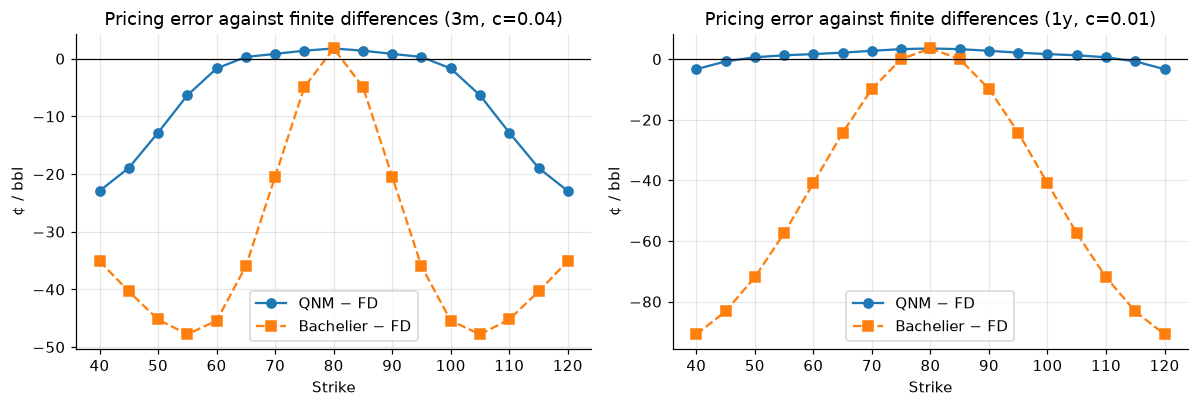

Max |QNM − FD| (¢), strikes 60–100: {'1y, c=0.01': 3.52, '3m, c=0.04': 1.78}
Max |QNM − FD| (¢), all strikes:    {'1y, c=0.01': 3.52, '3m, c=0.04': 22.94}
Max |Bachelier − FD| (¢):           {'1y, c=0.01': 90.8, '3m, c=0.04': 47.8}


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (name, (fd, q, bc)) in zip(axes, fig_data.items()):
    ax.plot(Ks, 100 * (q - fd), "o-", label="QNM − FD")
    ax.plot(Ks, 100 * (bc - fd), "s--", label="Bachelier − FD")
    ax.axhline(0, color="k", lw=0.8)
    ax.set(title=f"Pricing error against finite differences ({name})", xlabel="Strike", ylabel="¢ / bbl")
    ax.legend()
plt.tight_layout(); plt.show()
err = fd_tbl.assign(central=fd_tbl.K.between(60, 100))
print("Max |QNM − FD| (¢), strikes 60–100:", err[err.central].groupby("case")["QNM − FD (¢)"].apply(lambda s: s.abs().max()).round(2).to_dict())
print("Max |QNM − FD| (¢), all strikes:   ", err.groupby("case")["QNM − FD (¢)"].apply(lambda s: s.abs().max()).round(2).to_dict())
print("Max |Bachelier − FD| (¢):          ", err.groupby("case")["Bachelier − FD (¢)"].apply(lambda s: s.abs().max()).round(2).to_dict())

The closed form is accurate where it is used. For 3-month options it is within 1.8¢ between strikes 60 and 100. For 1-year options it is within 3.5¢ at every strike. Plain Bachelier misses by 20–90¢ over the same range.

The weak spot is the far 3-month wing. At strikes 40 and 120 the closed form prices the OTM option at about 14¢ against a true 37¢. A first-order perturbation cannot carry the large local volatility the parabola adds far from the vertex. The calibration window below stops at the 10-delta options (about ±19 dollars at 3 months), inside the accurate region. Anything priced off the far wings, such as deep OTM digitals or tail options, inherits this error.

## 4 · Which quotes go into the fit?

CME WTI options are American, and the inputs are settlement prices, while Black and Bachelier are European formulas.

1. Keep one OTM option per strike: puts below `F`, calls above. They carry most of the volatility information and the smallest early-exercise premium.
2. Remove the early-exercise premium (Barone-Adesi–Whaley, zero cost of carry) to obtain a European-equivalent price.
3. Invert Black for the implied Black vol (IBV) and Bachelier for the implied normal vol (INV, $/bbl).
4. Rank the listed expiries on each day: `m1…m4`.

In [5]:
cols = ["date", "opt_type", "strike", "expiry", "futures_price", "settlement"]
raw = pd.read_parquet(OPT_FILE, columns=cols)
raw = raw[raw.date.dt.dayofweek < 5]
fut_exp = raw[raw.date == raw.expiry].groupby("expiry").futures_price.first()   # futures settle on option expiry day

opt = raw.dropna(subset=["settlement", "futures_price"]).copy()
opt["tau"] = (opt.expiry - opt.date).dt.days / 365
opt = opt[opt.tau > 0]
opt["m"] = opt.groupby("date").expiry.rank(method="dense").astype(int)
opt["cp"] = np.where(opt.opt_type == "C", 1, -1)

otm = ((opt.cp == 1) & (opt.strike >= opt.futures_price)) | ((opt.cp == -1) & (opt.strike < opt.futures_price))
near = (opt.strike / opt.futures_price - 1).abs() <= 0.40
opt = opt[otm & near & (opt.settlement >= MIN_PRICE)].copy()
print(f"{len(opt):,} OTM option quotes | {opt.date.nunique()} days | {opt.date.min():%Y-%m-%d} → {opt.date.max():%Y-%m-%d}")
print("Expiries listed per day:", opt.groupby("date").m.max().value_counts().to_dict())

292,473 OTM option quotes | 763 days | 2023-05-16 → 2026-05-22
Expiries listed per day: {4: 630, 3: 133}


In [6]:
def baw_premium(F, K, tau, sig, cp, r=RATE):
    """Early-exercise premium of an American futures option (Barone-Adesi–Whaley, cost of carry b=0)."""
    F, K, tau, sig, cp = np.broadcast_arrays(*[np.asarray(v, float) for v in (F, K, tau, sig, cp)])
    e = np.exp(-r * tau)
    root = np.sqrt(1 + 4 * (2 * r / sig**2) / (1 - e))
    q = np.where(cp > 0, (1 + root) / 2, (1 - root) / 2)
    lo = np.where(cp > 0, K, K * 1e-3)
    hi = np.where(cp > 0, K * 10, K)
    for _ in range(50):                                        # bisection for the critical price S*
        S = (lo + hi) / 2
        d1 = (np.log(S / K) + 0.5 * sig**2 * tau) / (sig * np.sqrt(tau))
        gap = cp * (S - K) - black76(S, K, tau, sig, cp, r) - cp * (1 - e * ndtr(cp * d1)) * S / q
        move_up = cp * gap < 0
        lo = np.where(move_up, S, lo); hi = np.where(move_up, hi, S)
    S = (lo + hi) / 2
    d1 = (np.log(S / K) + 0.5 * sig**2 * tau) / (sig * np.sqrt(tau))
    A = cp * (S / q) * (1 - e * ndtr(cp * d1))
    exercised = cp * (F - S) >= 0
    prem = np.where(exercised, cp * (F - K) - black76(F, K, tau, sig, cp, r), A * (F / S) ** q)
    return np.maximum(prem, 0)


def implied_vol(price, F, K, tau, cp, model, lo, hi):
    """Vectorised bisection; `model` is black76 or bachelier."""
    lo = np.full(len(price), lo); hi = np.full(len(price), hi)
    for _ in range(60):
        mid = (lo + hi) / 2
        below = model(F, K, tau, mid, cp) < price
        lo = np.where(below, mid, lo); hi = np.where(below, hi, mid)
    return (lo + hi) / 2


def to_european(P, F, K, tau, cp):
    """Strip the early-exercise premium by iterating: IV -> premium -> European price -> IV."""
    sig = implied_vol(P, F, K, tau, cp, black76, 1e-4, 5.0)
    for _ in range(3):
        pe = P - baw_premium(F, K, tau, sig, cp)
        sig = implied_vol(pe, F, K, tau, cp, black76, 1e-4, 5.0)
    return pe, sig


F_, K_, t_, cp_, P_ = (opt[c].values.astype(float) for c in ["futures_price", "strike", "tau", "cp", "settlement"])
opt["price_eur"], opt["ibv"] = to_european(P_, F_, K_, t_, cp_)
opt["inv"] = implied_vol(opt.price_eur.values, F_, K_, t_, cp_, bachelier, 1e-3, 500.0)
opt["eep"] = opt.settlement - opt.price_eur
opt = opt[(opt.price_eur > 0.02) & opt.ibv.between(0.02, 4.9) & opt.inv.between(0.01, 499)].copy()
print(f"{len(opt):,} quotes kept after cleaning")

292,473 quotes kept after cleaning


**Size of the early-exercise adjustment.** A large premium would bias every implied vol, so its size is checked first.

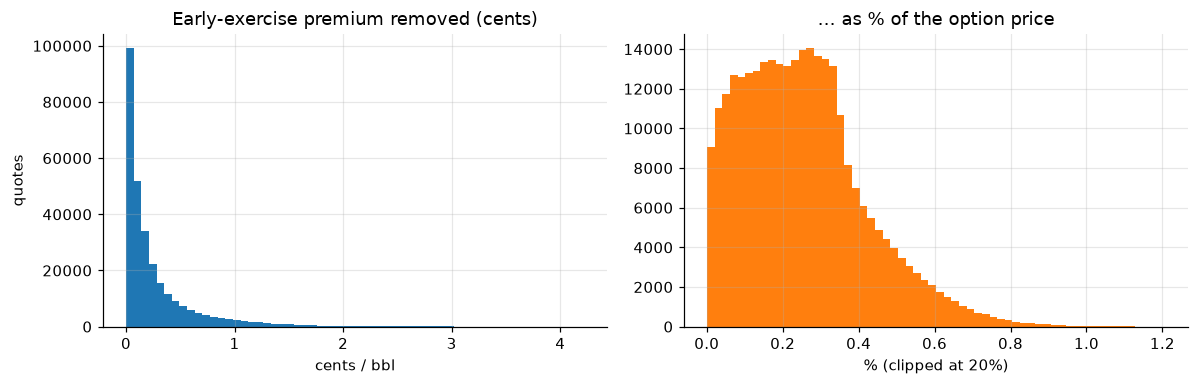

{'count': 29247300.0, 'mean': 0.27, 'std': 0.38, 'min': 0.0, '50%': 0.13, '90%': 0.72, '99%': 1.83, 'max': 4.22} ← cents
Median premium as % of price: 0.24% | 99th pct: 0.73%
Mean premium by maturity rank (cents): {1: 0.03, 2: 0.13, 3: 0.32, 4: 0.55}


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(100 * opt.eep, bins=60, color="tab:blue")
ax[0].set(title="Early-exercise premium removed (cents)", xlabel="cents / bbl", ylabel="quotes")
rel = (opt.eep / opt.settlement).clip(0, 0.2)
ax[1].hist(100 * rel, bins=60, color="tab:orange")
ax[1].set(title="… as % of the option price", xlabel="% (clipped at 20%)")
plt.tight_layout(); plt.show()
print(opt.eep.describe(percentiles=[.5, .9, .99]).mul(100).round(2).to_dict(), "← cents")
print("Median premium as % of price:", f"{(opt.eep / opt.settlement).median():.2%}", "| 99th pct:", f"{(opt.eep / opt.settlement).quantile(.99):.2%}")
print("Mean premium by maturity rank (cents):", (opt.groupby("m").eep.mean() * 100).round(2).to_dict())

The premium is small: a median of 0.24% of the option price and under 1% at the 99th percentile. It grows with maturity (`m1` 0.03¢, `m4` 0.55¢), as expected with a 5% rate. The conversion is a minor correction and does not bias the implied vols.

## 5 · Is the smile normal or lognormal?

For each day and expiry, vols are interpolated on a delta grid: 10/20/30/40-delta puts (`10p…40p`), ATM, and 40/30/20/10-delta calls (`40c…10c`). `σ_A` is the INV at `K = F`.

In [8]:
GRID = {"10p": 0.9, "20p": 0.8, "30p": 0.7, "40p": 0.6, "40c": 0.4, "30c": 0.3, "20c": 0.2, "10c": 0.1}
ORDER = ["10p", "20p", "30p", "40p", "ATM", "40c", "30c", "20c", "10c"]


def summarise_group(g):
    g = g.sort_values("strike")
    F, K, tau = g.futures_price.iloc[0], g.strike.values, g.tau.iloc[0]
    if len(g) < 8 or K[0] >= F or K[-1] <= F:
        return None
    ibv, inv = g.ibv.values, g.inv.values
    dcall = ndtr((np.log(F / K) + 0.5 * ibv**2 * tau) / (ibv * np.sqrt(tau)))   # call delta, falls with strike
    o = np.argsort(dcall)
    row = {"F": F, "tau": tau, "m": g.m.iloc[0], "n": len(g),
           "sigA": np.interp(F, K, inv), "ibvA": np.interp(F, K, ibv)}
    for k, d in GRID.items():
        row[f"ibv_{k}"] = np.interp(d, dcall[o], ibv[o], left=np.nan, right=np.nan)
        row[f"inv_{k}"] = np.interp(d, dcall[o], inv[o], left=np.nan, right=np.nan)
    row["ibv_ATM"], row["inv_ATM"] = row["ibvA"], row["sigA"]
    return row


rows = {k: summarise_group(g) for k, g in opt.groupby(["date", "expiry"])}
grp = pd.DataFrame({k: v for k, v in rows.items() if v is not None}).T
grp.index.names = ["date", "expiry"]
grp = grp.astype({c: float for c in grp.columns if c != "m"}).astype({"m": int}).reset_index()
grp["date"] = pd.to_datetime(grp.date); grp["expiry"] = pd.to_datetime(grp.expiry)
print(f"{len(grp):,} day × expiry smiles | days per rank:", grp.m.value_counts().sort_index().to_dict())

2,916 day × expiry smiles | days per rank: {1: 760, 2: 763, 3: 763, 4: 630}


In [9]:
def smile_stats(m, kind):
    cols = [f"{kind}_{k}" for k in ORDER]
    s = full[full.m == m][cols].describe().T[["mean", "std", "min", "max"]]
    s.index = ORDER
    return s.round(3 if kind == "inv" else 4)

# only days where all nine delta points exist, so every bucket averages the same days
full = grp.dropna(subset=[f"{k}_{g}" for k in ("ibv", "inv") for g in ORDER]).copy()
full["year"] = full.date.dt.year
print("Share of smiles with all nine points, by year:", (grp.assign(ok=grp.index.isin(full.index)).groupby(grp.date.dt.year).ok.mean().round(2)).to_dict())

stats = pd.concat({f"m{m} {kind.upper()}": smile_stats(m, kind) for m in (3, 4) for kind in ("ibv", "inv")}, axis=1)
stats

Share of smiles with all nine points, by year: {2023: 0.99, 2024: 0.99, 2025: 0.98, 2026: 0.33}


m3 IBV                       m3 INV                        m4 IBV                       m4 INV                       
      mean    std    min    max    mean    std     min     max   mean    std    min    max    mean    std     min     max
10p 0.3776 0.0514 0.2580 0.6270 23.9810 3.1020 17.8570 35.5480 0.3794 0.0468 0.2769 0.5864 23.5830 2.6960 18.1550 31.5390
20p 0.3432 0.0459 0.2354 0.5446 22.7720 3.1600 16.7990 34.5990 0.3443 0.0415 0.2517 0.5109 22.5160 2.7780 17.0600 30.9140
30p 0.3267 0.0433 0.2259 0.4971 22.2650 3.1860 16.4290 34.8080 0.3266 0.0389 0.2386 0.4677 22.0270 2.7900 16.7040 30.9070
40p 0.3164 0.0417 0.2197 0.4628 22.0150 3.2130 16.4260 35.3870 0.3148 0.0369 0.2306 0.4347 21.7470 2.7740 16.7270 31.1720
ATM 0.3112 0.0414 0.2153 0.4466 21.9340 3.2450 16.4990 35.9640 0.3088 0.0363 0.2249 0.4227 21.6410 2.7640 16.8290 31.4900
40c 0.3055 0.0412 0.2111 0.4357 22.0360 3.3900 16.8090 37.8990 0.3008 0.0347 0.2186 0.3934 21.6640 2.7820 17.1730 32.7940
30c 0.3047 0.0427 0.2084 0.4542 22.4100 3.6130 17.0150 40.2580 0.2985 0.0347 0.2172 0.3921 21.9670 2.8520 17.4670 34.5460
20c 0.3096 0.0466 0.2107 0.4857 23.3190 4.0690 17.4740 44.0590 0.3018 0.0363 0.2185 0.4124 22.8160 3.0700 17.9750 37.7230
10c 0.3321 0.0578 0.2261 0.5551 26.0450 5.3070 18.8230 52.5190 0.3223 0.0438 0.2311 0.4632 25.4720 3.8200 19.3540 45.1430

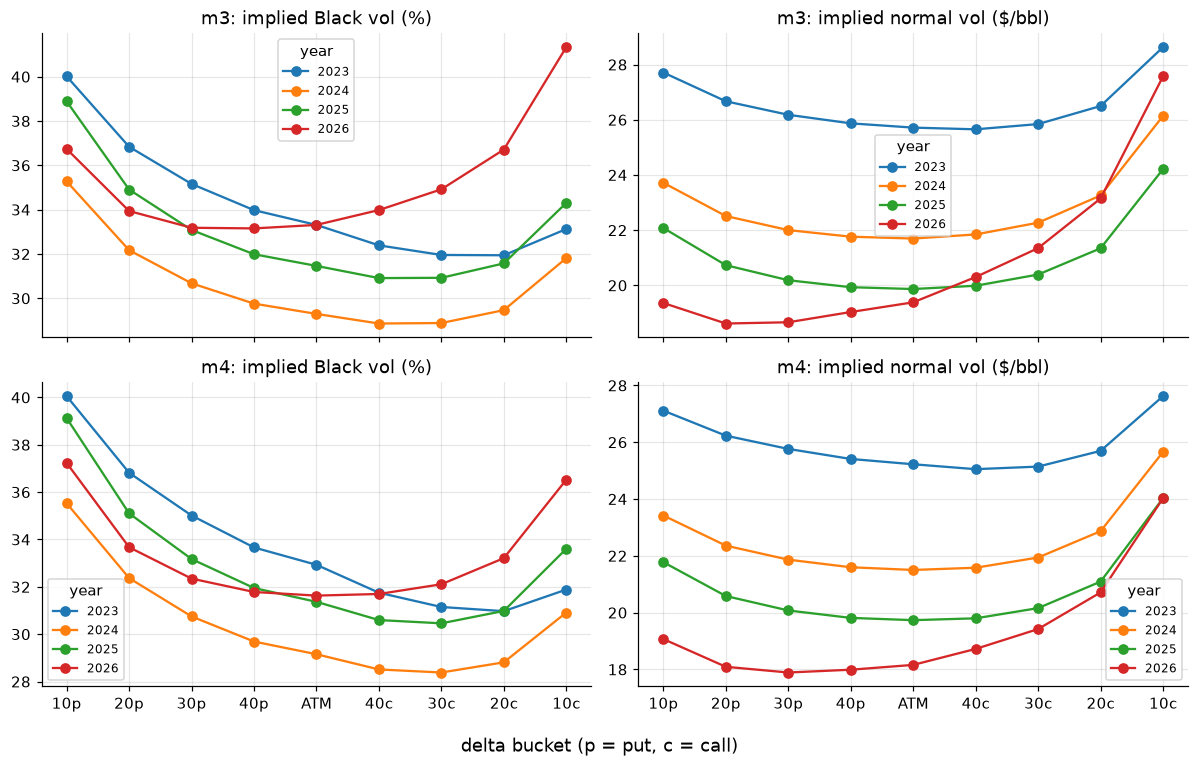

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for i, m in enumerate((3, 4)):
    for j, kind in enumerate(("ibv", "inv")):
        ax = axes[i, j]
        for y, gy in full[full.m == m].groupby("year"):
            ax.plot(ORDER, gy[[f"{kind}_{k}" for k in ORDER]].mean().values * (100 if kind == "ibv" else 1), "o-", label=str(y))
        ax.set(title=f"m{m}: {'implied Black vol (%)' if kind == 'ibv' else 'implied normal vol ($/bbl)'}")
        ax.legend(title="year", fontsize=8)
fig.supxlabel("delta bucket (p = put, c = call)")
plt.tight_layout(); plt.show()

In [11]:
# Wing asymmetry by year: how far each 10-delta wing sits above ATM, in each vol measure
wing = full.assign(year=full.date.dt.year).groupby(["m", "year"]).apply(lambda d: pd.Series({
    "IBV put wing": (d.ibv_10p / d.ibv_ATM - 1).mean(), "IBV call wing": (d.ibv_10c / d.ibv_ATM - 1).mean(),
    "INV put wing": (d.inv_10p / d.inv_ATM - 1).mean(), "INV call wing": (d.inv_10c / d.inv_ATM - 1).mean(),
    "days": len(d)}))
wing.loc[[3, 4]].style.format({c: "{:+.1%}" for c in wing.columns if "wing" in c} | {"days": "{:.0f}"})

In Black vol the smile is a steep put skew (10-delta put about 38%, 10-delta call about 33%). In normal vol the put wing shrinks, but the call wing is larger in every year: for `m3`, +19.6% vs +9.8% above ATM in 2024, +21.7% vs +11.1% in 2025, and +40.7% vs +0.9% in 2026. Normal vol removes the lognormal put bias but leaves a persistent call wing, which the 2026 spike amplifies.

In 2026 only about a third of the days have a complete grid, because the 10-delta call moves beyond the ±40% strike window once volatility spikes. Averages use complete smiles only.

## 6 · How is the smile fitted each day?

For each day and expiry:
1. fix `σ_A` from the ATM point;
2. keep OTM options inside the 10-delta window (`|m| ≤ 1.28`);
3. fit level, slope and curvature by least squares on prices, in the at-the-money form `k = K − F` (well conditioned), then convert to `(a, b, c)` and `(A, F0, c)`.

**Convexity floor.** When `c < 0.001` the smile is nearly linear and `F0 = −b/2c` is meaningless. The fit is repeated with `c = 0.001` and the day flagged as low convexity.

In [12]:
opt = opt.merge(grp[["date", "expiry", "sigA", "ibvA"]], on=["date", "expiry"], how="inner")
opt["x"] = (opt.strike - opt.futures_price) / (opt.sigA * np.sqrt(opt.tau))   # normal moneyness (K−F in std devs)
opt["use"] = opt.x.abs() <= MAX_ABS_M


def calibrate(g, cmin=CMIN, r=RATE):
    F, tau, sA = g.futures_price.iloc[0], g.tau.iloc[0], g.sigA.iloc[0]
    K, cp, P = g.strike.values, g.cp.values, g.price_eur.values
    k = K - F
    w = np.exp(-r * tau) * np.sqrt(tau) * npdf(-k / (sA * np.sqrt(tau)))
    y = P - bachelier(F, K, tau, sA, cp, r)
    X = np.column_stack([w, w * k / 2, w * (k**2 / 3 + sA**2 * tau / 6)])
    coef = np.linalg.lstsq(X / X.std(0), y, rcond=None)[0] / X.std(0)     # y ≈ w·(a' + b'k/2 + c(k²/3 + σ²τ/6))
    a1, b1, c_free = coef
    if c_free < cmin:
        y2 = y - cmin * X[:, 2]
        sc = X[:, :2].std(0)
        a1, b1 = np.linalg.lstsq(X[:, :2] / sc, y2, rcond=None)[0] / sc
        c = cmin
    else:
        c = c_free
    a, b = a1 - b1 * F + c * F**2, b1 - 2 * c * F                         # back to absolute (a, b)
    A, F0, _ = to_AF0c(a, b, c)
    fit = qnm_price(F, K, tau, sA, a, b, c, cp, r)
    return dict(F=F, tau=tau, sigA=sA, ibvA=g.ibvA.iloc[0], n=len(g), a=a, b=b, c=c, A=A, F0=F0,
                lvl=a1, slope=b1,                                              # local-vol shift and slope at F
                c_free=c_free, low=c_free < cmin, rmse=np.sqrt(np.mean((fit - P) ** 2)))


fits = {k: calibrate(g) for k, g in opt[opt.use].groupby(["date", "expiry"]) if len(g) >= 8}
cal = pd.DataFrame(fits).T
cal.index.names = ["date", "expiry"]
cal = cal.reset_index()
for c_ in ["date", "expiry"]:
    cal[c_] = pd.to_datetime(cal[c_])
cal = cal.astype({c_: float for c_ in cal.columns if c_ not in ("date", "expiry", "low")}).astype({"low": bool})
cal = cal.merge(grp[["date", "expiry", "m"]], on=["date", "expiry"])
cal["F0_minus_F"] = cal.F0 - cal.F
print(f"{len(cal):,} daily fits | low-convexity share: {cal.low.mean():.1%}")
cal.groupby("m").agg(days=("c", "size"), low_share=("low", "mean"), fit_rmse_cents=("rmse", lambda s: 100 * s.mean())).round(3)

2,891 daily fits | low-convexity share: 0.0%


,days,low_share,fit_rmse_cents
m,,,
1,735,0.0000,0.9430
2,763,0.0000,1.5940
3,763,0.0000,1.8260
4,630,0.0000,2.1060


## 7 · How well does it fit, in and out of sample?

Error is model price minus market price (positive means the model is too high). All three models are scored on the same OTM options:
- **Black:** one flat ATM IBV;
- **Bachelier:** one flat ATM INV;
- **QNM:** ATM INV plus the fitted parameters.

Horizons: `T` is in-sample. For `T+1` and `T+5`, the day-T parameters are frozen and options are repriced 1 and 5 trading days later with the new futures price and shorter maturity.

In [13]:
dts = np.array(sorted(opt.date.unique()))


def evaluate(h):
    origin = pd.Series(dts[: len(dts) - h], index=dts[h:])
    e = opt[opt.use].copy()
    e["orig"] = e.date.map(origin)
    par = cal[["date", "expiry", "sigA", "ibvA", "a", "b", "c"]].rename(
        columns={"date": "orig", "sigA": "sA0", "ibvA": "iA0"})
    e = e.dropna(subset=["orig"]).merge(par, on=["orig", "expiry"])
    F, K, t, cp = (e[v].values for v in ["futures_price", "strike", "tau", "cp"])
    out = pd.DataFrame({"m": e.m.values, "x": e.x.values, "date": e.date.values, "h": h, "mkt": e.price_eur.values})
    out["Black"] = black76(F, K, t, e.iA0.values, cp) - out.mkt
    out["Bachelier"] = bachelier(F, K, t, e.sA0.values, cp) - out.mkt
    out["QNM"] = qnm_price(F, K, t, e.sA0.values, e.a.values, e.b.values, e.c.values, cp) - out.mkt
    return out


ev = pd.concat([evaluate(h) for h in (0, 1, 5)], ignore_index=True)
MODELS = ["Black", "Bachelier", "QNM"]


def metrics(d):
    return pd.Series({f"{mo} {s}": v for mo in MODELS for s, v in
                      zip(("ME", "MAE", "RMSE"), (d[mo].mean(), d[mo].abs().mean(), np.sqrt((d[mo] ** 2).mean())))})

tbl = ev[ev.m.isin([2, 3, 4])].groupby(["m", "h"]).apply(metrics).round(4)
tbl.rename(index={0: "T (in-sample)", 1: "T+1", 5: "T+5"}, level=1)

Black ME  Black MAE  Black RMSE  Bachelier ME  Bachelier MAE  Bachelier RMSE  QNM ME  QNM MAE  QNM RMSE
m h                                                                                                                     
2 T (in-sample)   -0.0777     0.2071      0.3116       -0.0771         0.3162          0.5800 -0.0004   0.0233    0.0501
  T+1             -0.1015     0.2545      0.4185       -0.1125         0.3687          0.7001 -0.0005   0.1175    0.2088
  T+5             -0.1981     0.4246      0.7834       -0.2501         0.5303          1.0529 -0.0257   0.2864    0.5133
3 T (in-sample)   -0.1032     0.2286      0.3305       -0.1046         0.3087          0.5851 -0.0003   0.0221    0.0424
  T+1             -0.1205     0.2669      0.4126       -0.1310         0.3511          0.6768 -0.0027   0.1059    0.1816
  T+5             -0.1915     0.4051      0.6997       -0.2350         0.4818          0.9522 -0.0318   0.2652    0.4601
4 T (in-sample)   -0.1136     0.2436      0.3358       -0.1157         0.2790          0.5396 -0.0002   0.0221    0.0360
  T+1             -0.1311     0.2778      0.4025       -0.1390         0.3170          0.6151 -0.0063   0.1034    0.1758
  T+5             -0.2435     0.4311      0.7183       -0.2695         0.4586          0.9293 -0.0750   0.2834    0.4747

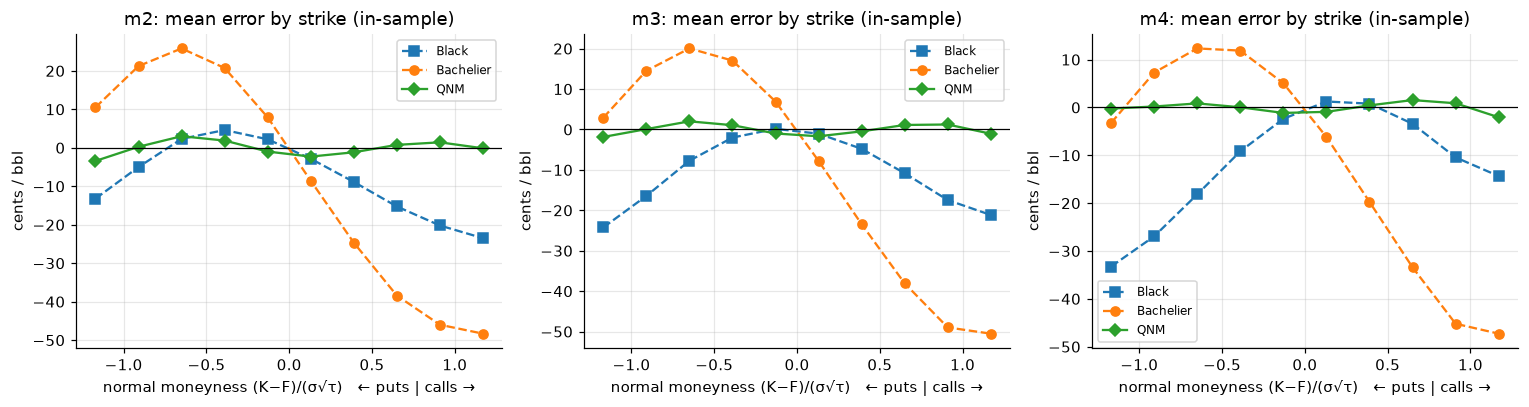

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, m in zip(axes, (2, 3, 4)):
    d = ev[(ev.m == m) & (ev.h == 0)].copy()
    d["bin"] = pd.cut(d.x, np.arange(-1.3, 1.31, 0.26))
    mean_err = d.groupby("bin", observed=True)[MODELS].mean()
    mid = [iv.mid for iv in mean_err.index]
    for mo, st in zip(MODELS, ["s--", "o--", "D-"]):
        ax.plot(mid, 100 * mean_err[mo], st, label=mo)
    ax.axhline(0, color="k", lw=0.8)
    ax.set(title=f"m{m}: mean error by strike (in-sample)", xlabel="normal moneyness (K−F)/(σ√τ)   ← puts | calls →", ylabel="cents / bbl")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

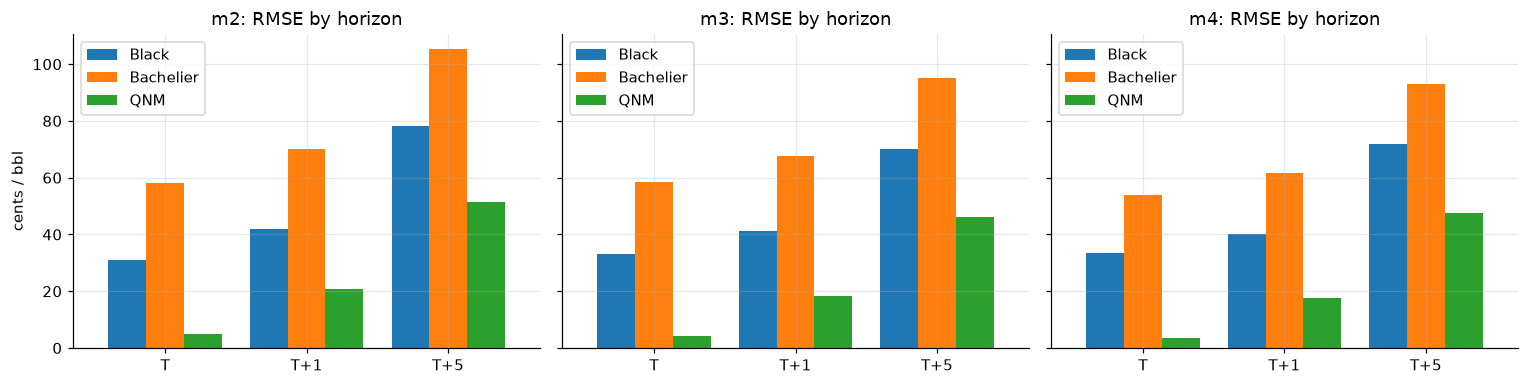

In-sample RMSE ratio vs QNM (×):
    Black  Bachelier
m                  
2 6.2200    11.5800
3 7.8000    13.8100
4 9.3300    15.0000


In [15]:
rm = (ev[ev.m.isin([2, 3, 4])].groupby(["m", "h"])[MODELS]
      .apply(lambda d: np.sqrt((d**2).mean())).mul(100).reset_index())
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, m in zip(axes, (2, 3, 4)):
    d = rm[rm.m == m].set_index("h")[MODELS]
    d.index = ["T", "T+1", "T+5"]
    d.plot.bar(ax=ax, rot=0, width=0.8)
    ax.set(title=f"m{m}: RMSE by horizon", ylabel="cents / bbl")
plt.tight_layout(); plt.show()
ratio = (rm[rm.h == 0].set_index("m")[["Black", "Bachelier"]].div(rm[rm.h == 0].set_index("m")["QNM"], axis=0)).round(2)
print("In-sample RMSE ratio vs QNM (×):\n", ratio)

In [16]:
# RMSE by calendar year, m3, in-sample
yr = ev[(ev.m == 3) & (ev.h == 0)].assign(year=lambda d: pd.to_datetime(d.date).dt.year)
by_year = yr.groupby("year")[MODELS].apply(lambda d: np.sqrt((d**2).mean())).mul(100)
by_year["quotes"] = yr.groupby("year").size()
by_year["Bachelier ÷ Black"] = by_year.Bachelier / by_year.Black
by_year.style.format({**{m: "{:.1f}" for m in MODELS}, "quotes": "{:,.0f}", "Bachelier ÷ Black": "{:.2f}"})

,Black,Bachelier,QNM,quotes,Bachelier ÷ Black
year,,,,,
2023,24.0,15.7,1.5,"9,635",0.65
2024,18.3,15.9,1.2,"12,855",0.87
2025,19.2,17.4,1.3,"11,894",0.91
2026,59.0,120.5,8.7,"9,777",2.04


The single-vol models leave a systematic, strike-dependent error, and the QNM removes it across the strike range. In-sample RMSE falls by a factor of 6–9 against Black and 12–15 against Bachelier. One day later the QNM keeps most of its edge. After five days the edge shrinks, because the futures price has moved away from the parabola's vertex, so the parameters need refitting every day or two.

Over the full sample a single Bachelier vol looks worse than a single Black vol, but the yearly table shows that this comes from 2026 alone. In 2023–2025 Bachelier is better every year (RMSE ratio 0.65–0.91), so normal vol is the better base in ordinary markets. In 2026 the call wing grows to +41% above ATM and a flat normal vol under-prices those calls badly (120.5¢ RMSE against 59.0¢ for Black). The QNM fits to 1.2–1.5¢ in 2023–2025 and 8.7¢ in 2026.

## 8 · How do the parameters move?

### 8.1 · Why is the vertex form unstable?
The calibration pins local volatility at the futures price close to `σ_A`, so `A + c(F − F0)²` stays small. That forces `A ≈ −c(F − F0)²`: any co-movement between `A` and `F0 − F` is algebra, not market behaviour. When `c` falls, `F0 = F − s/(2c)` also moves far away purely through the division. The check below measures how much of `A` the identity explains.

m3: corr(A, −c(F−F0)²) = 0.998;  median |A − (−c(F−F0)²)| = 0.719 vs median |A| = 0.836


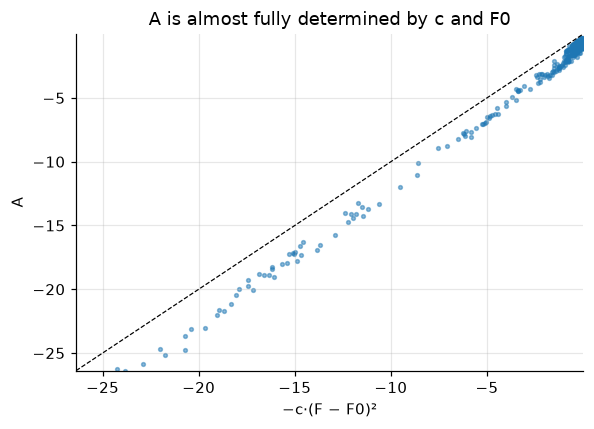

In [17]:
c3 = cal[cal.m == 3].sort_values("date").reset_index(drop=True)
ident = -c3.c * (c3.F - c3.F0) ** 2
print(f"m3: corr(A, −c(F−F0)²) = {np.corrcoef(c3.A, ident)[0, 1]:.3f};  "
      f"median |A − (−c(F−F0)²)| = {np.median(np.abs(c3.A - ident)):.3f} vs median |A| = {np.median(np.abs(c3.A)):.3f}")
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(ident, c3.A, s=6, alpha=0.5)
lim = np.percentile(np.r_[ident, c3.A], [1, 99.5]); ax.plot(lim, lim, "k--", lw=0.8)
ax.set(xlim=lim, ylim=lim, xlabel="−c·(F − F0)²", ylabel="A", title="A is almost fully determined by c and F0")
plt.tight_layout(); plt.show()

By definition `A = ℓ − c(F − F0)²`. The 0.998 correlation comes from the extreme days, when `c(F − F0)²` is large. On a typical day `A` is mostly the level `ℓ` (median gap 0.72 against a median |A| of 0.84). The large swings of `A` and `F0` are therefore artefacts of the vertex form, not separate market moves.

### 8.2 · What do level, slope and curvature show?
These three numbers are what the market quotes, and they stay finite when the smile is linear:
- **level** `ℓ`: local-vol shift at `F` (ATM straddle relative to `σ_A`);
- **slope** `s`: local-vol slope at `F` (risk reversal; positive means call skew);
- **curvature** `c` (strangle).

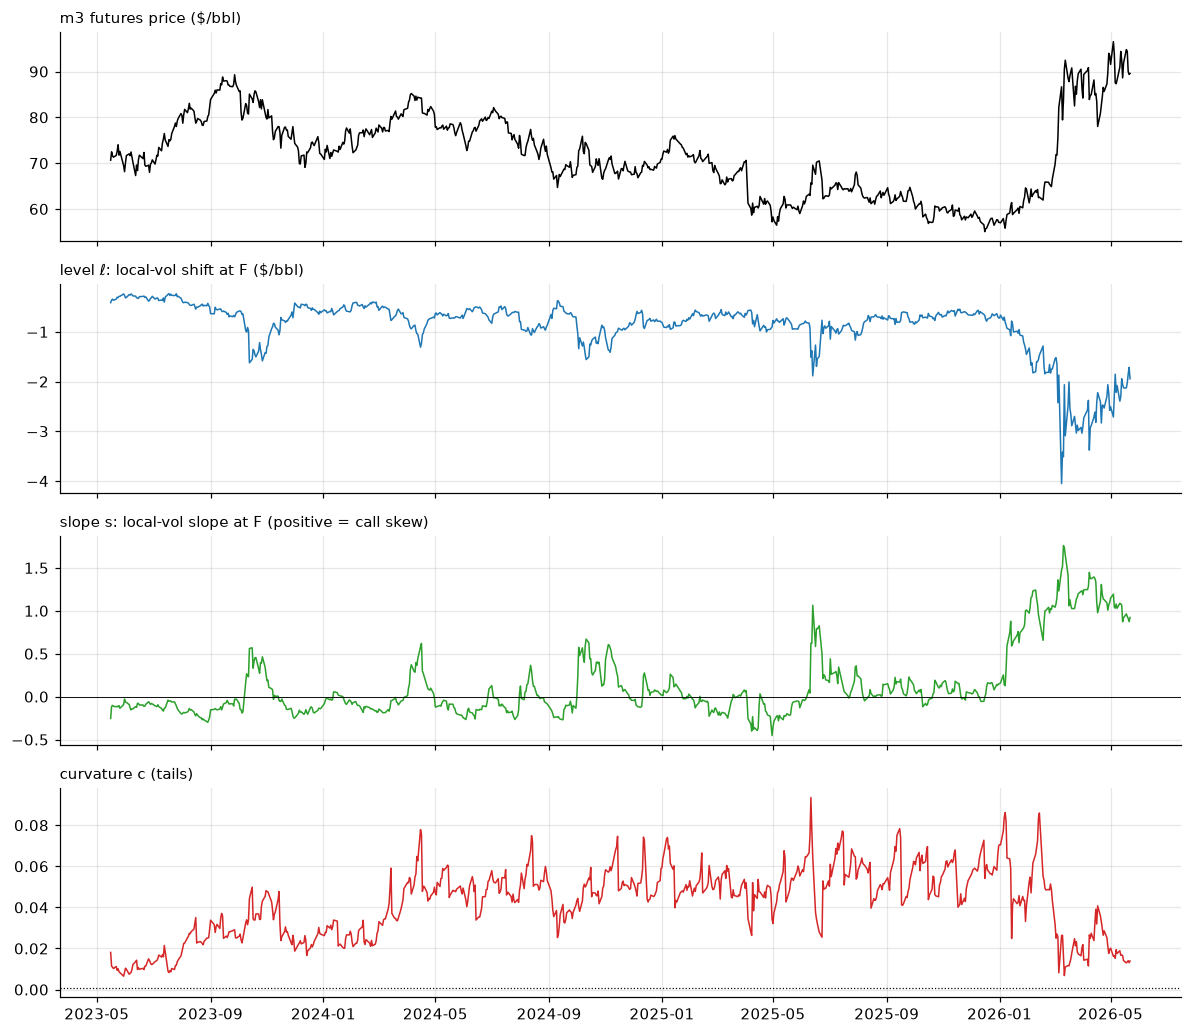

Rank correlation, m3 (at-the-money form):
          lvl   slope       c
lvl    1.0000 -0.7600 -0.3400
slope -0.7600  1.0000  0.2300
c     -0.3400  0.2300  1.0000


m                       1         2         3        4
lvl        mean   -0.9256   -0.9197   -0.8877  -0.8284
           std     0.6255    0.6208    0.5629   0.5056
           min    -5.4724   -6.0073   -4.0511  -3.5381
           50%    -0.7156   -0.7215   -0.7188  -0.6934
           max    -0.2884   -0.2400   -0.2325  -0.1948
slope      mean    0.2264    0.1780    0.1329   0.0922
           std     1.1846    0.5701    0.4085   0.3226
           min    -3.7648   -0.8295   -0.4532  -0.3027
           50%    -0.0702   -0.0182   -0.0086  -0.0189
           max     8.5616    2.3721    1.7596   1.3922
c          mean    0.3153    0.0711    0.0424   0.0303
           std     0.4315    0.0328    0.0171   0.0110
           min     0.0049    0.0054    0.0065   0.0052
           50%     0.1809    0.0724    0.0456   0.0328
           max     5.1550    0.1723    0.0934   0.0605
A          mean   -3.8979   -4.0027   -2.8638  -2.1533
           std    10.0177   12.4997    7.2866   4.5444
           min   -92.7515 -243.1555 -112.8362 -47.2143
           50%    -0.9831   -0.8788   -0.8357  -0.7832
           max    -0.3287   -0.4290   -0.2926  -0.2402
F0_minus_F mean   -2.4806   -3.1932   -2.4656  -1.7814
           std    11.4821   13.9288   10.6275   8.3159
           min  -136.4196 -211.0747 -127.5012 -64.1559
           50%     0.1510    0.1022    0.0925   0.3016
           max     6.9285    8.0325    9.1908   8.1917

In [18]:
fig, axes = plt.subplots(4, 1, figsize=(11, 9.5), sharex=True)
series = [("F", "m3 futures price ($/bbl)", "k"), ("lvl", "level ℓ: local-vol shift at F ($/bbl)", "tab:blue"),
          ("slope", "slope s: local-vol slope at F (positive = call skew)", "tab:green"), ("c", "curvature c (tails)", "tab:red")]
for ax, (col, title, colr) in zip(axes, series):
    ax.plot(c3.date, c3[col], color=colr, lw=1)
    ax.fill_between(c3.date, 0, 1, where=c3.low, transform=ax.get_xaxis_transform(), color="grey", alpha=0.3, lw=0)
    ax.set_title(title, loc="left", fontsize=10)
axes[2].axhline(0, color="k", lw=0.6); axes[3].axhline(CMIN, color="k", ls=":", lw=0.8)
plt.tight_layout(); plt.show()

good = cal[~cal.low]
print("Rank correlation, m3 (at-the-money form):")
print(good[good.m == 3][["lvl", "slope", "c"]].corr(method="spearman").round(2))
good.groupby("m")[["lvl", "slope", "c", "A", "F0_minus_F"]].describe().T.loc[(slice(None), ["mean", "std", "min", "50%", "max"]), :].round(4)

- **Curvature falls with maturity:** median about 0.046 for `m3` and 0.033 for `m4`. It multiplies `τ` in the price, and longer horizons carry thinner tails.
- **The floor never binds.** Every day in this sample has a clear parabolic smile. Low-convexity days are expected when prices are low and the smile turns linear, and the sample stays above $55.
- **The slope carries the regime change.** Its median is −0.01: near zero through 2023–2025, with short call-skew spikes (late 2023, spring and autumn 2024, June 2025). From February 2026 it holds between 0.6 and 1.8 as the call skew builds.
- **Level and curvature move with it.** Level stays around −0.7 until 2026, then falls to between −2 and −4. Curvature rises from about 0.015 in mid-2023 to 0.04–0.08 in 2024–2025, and drops back to about 0.015 in 2026 as the smile becomes a straight call skew. In vertex form the same episode shows up as `F0` far below `F` and a large negative `A`.
- **`m1` is unstable** (curvature up to 5), as expected for options days from expiry. The analysis focuses on `m2–m4`.

m3 days below the convexity floor: 0 of 763
m3 futures price range in the sample: $55 – $97


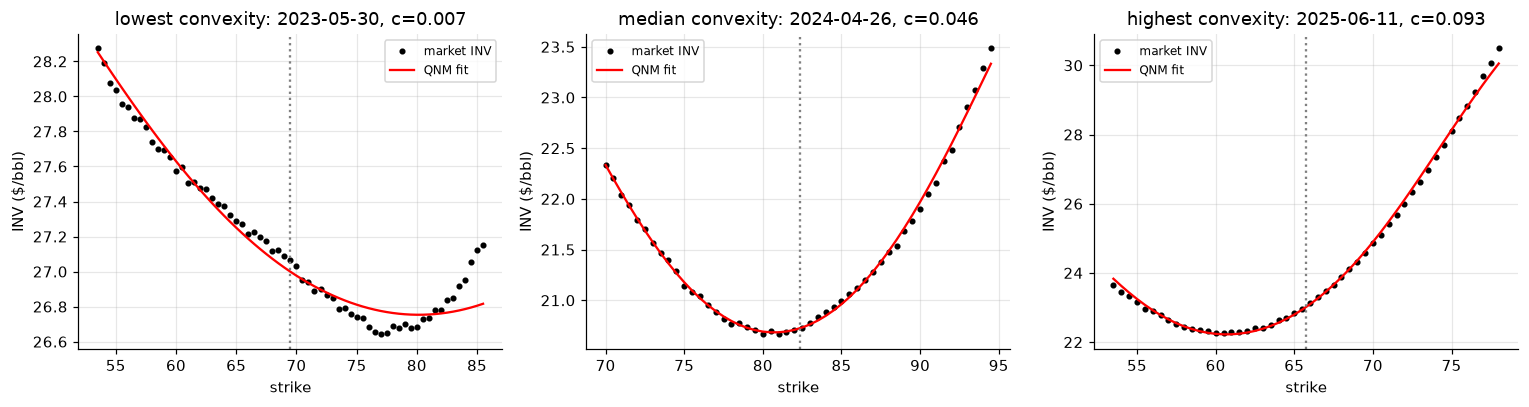

In [19]:
low_days = c3[c3.low]
print(f"m3 days below the convexity floor: {len(low_days)} of {len(c3)}")
print(f"m3 futures price range in the sample: ${c3.F.min():.0f} – ${c3.F.max():.0f}")

pick = c3.sort_values("c_free").iloc[[0, len(c3) // 2, -1]]
labels = ["lowest convexity", "median convexity", "highest convexity"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, lab, (_, r) in zip(axes, labels, pick.iterrows()):
    g = opt[(opt.date == r.date) & (opt.expiry == r.expiry) & opt.use].sort_values("strike")
    qm = qnm_price(r.F, g.strike.values, r.tau, r.sigA, r.a, r.b, r.c, g.cp.values)
    ax.plot(g.strike, g.inv, "ko", ms=3, label="market INV")
    ax.plot(g.strike, implied_vol(qm, r.F, g.strike.values, r.tau, g.cp.values, bachelier, 1e-3, 500.0), "r-", label="QNM fit")
    ax.axvline(r.F, color="grey", ls=":")
    ax.set(title=f"{lab}: {r.date:%Y-%m-%d}, c={r.c_free:.3f}", xlabel="strike", ylabel="INV ($/bbl)")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Low curvature is a nearly straight normal-vol smile, and high curvature is a deep U with expensive wings.

## 9 · What do digital option prices add?

A digital pays $1 if `F_T > K`. Its value is the risk-neutral probability `D = −∂C/∂K`, which has a closed form under the QNM:

`D = N(m) − √τ·n(m)·(b/2 + c(F+2K)/3) − (F−K)/(σ_A²√τ)·n(m)·(v + c·σ_A²τ/6)`

At the money it reduces to `D_ATM = 0.5 − √(τ/2π)·s/2`: the ATM digital depends only on the local-vol slope `s` at the futures price (in vertex form, `0.5 − √(τ/2π)·c·(F − F0)`). Bachelier always gives 0.50, and Black always gives `N(−σ√τ/2) < 0.50`. The closed form is checked against a numerical derivative first.

max |analytic − numeric| digital: 2.89e-08


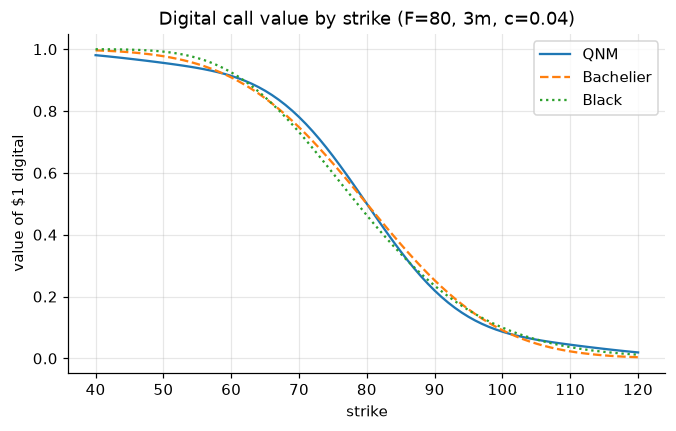

In [20]:
def qnm_digital(F, K, tau, sig, a, b, c):
    """Risk-neutral P(F_T > K), no discounting."""
    m = (F - K) / (sig * np.sqrt(tau))
    v = a + b / 2 * (K + F) + c / 3 * (K**2 + K * F + F**2)
    return (ndtr(m) - np.sqrt(tau) * npdf(m) * (b / 2 + c * (F + 2 * K) / 3)
            - (F - K) / (sig**2 * np.sqrt(tau)) * npdf(m) * (v + c / 6 * sig**2 * tau))


F_, sig_, tau_, c_ = 80.0, 30.0, 0.25, 0.04
a_, b_, _ = to_abc(-1.5, 80.0, c_)
Kgrid = np.arange(40, 121, 1.0)
eps = 0.01
num = -(qnm_price(F_, Kgrid + eps, tau_, sig_, a_, b_, c_, 1, r=0) - qnm_price(F_, Kgrid - eps, tau_, sig_, a_, b_, c_, 1, r=0)) / (2 * eps)
ana = qnm_digital(F_, Kgrid, tau_, sig_, a_, b_, c_)
print(f"max |analytic − numeric| digital: {np.abs(ana - num).max():.2e}")

blk = ndtr(np.log(F_ / Kgrid) / (sig_ / F_ * np.sqrt(tau_)) - sig_ / F_ * np.sqrt(tau_) / 2)
bch = ndtr((F_ - Kgrid) / (sig_ * np.sqrt(tau_)))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Kgrid, ana, label="QNM"); ax.plot(Kgrid, bch, "--", label="Bachelier"); ax.plot(Kgrid, blk, ":", label="Black")
ax.set(title="Digital call value by strike (F=80, 3m, c=0.04)", xlabel="strike", ylabel="value of $1 digital")
ax.legend(); plt.show()

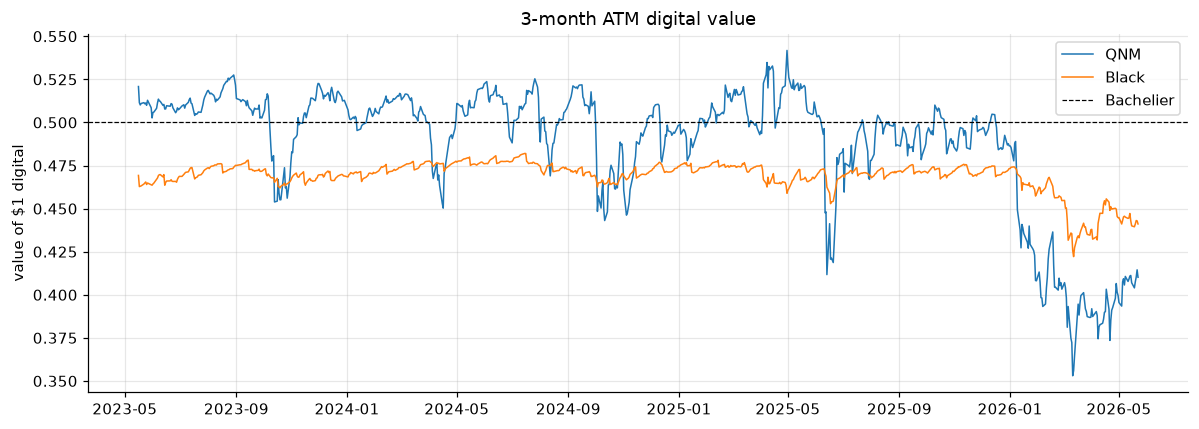

       dig_qnm  dig_blk
count 763.0000 763.0000
mean    0.4880   0.4688
std     0.0368   0.0092
min     0.3530   0.4222
25%     0.4833   0.4673
50%     0.5008   0.4710
75%     0.5112   0.4742
max     0.5418   0.4820


In [21]:
cal["dig_qnm"] = qnm_digital(cal.F, cal.F, cal.tau, cal.sigA, cal.a, cal.b, cal.c)
cal["dig_blk"] = ndtr(-cal.ibvA * np.sqrt(cal.tau) / 2)
c3 = cal[cal.m == 3].sort_values("date")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(c3.date, c3.dig_qnm, label="QNM", lw=1)
ax.plot(c3.date, c3.dig_blk, label="Black", lw=1)
ax.axhline(0.5, color="k", ls="--", lw=0.8, label="Bachelier")
ax.fill_between(c3.date, 0, 1, where=c3.low, transform=ax.get_xaxis_transform(), color="grey", alpha=0.3, lw=0)
ax.set(title="3-month ATM digital value", ylabel="value of $1 digital")
ax.legend(); plt.tight_layout(); plt.show()
print(c3[["dig_qnm", "dig_blk"]].describe().round(4))

The QNM digital moves on both sides of 0.50, while Black stays below and Bachelier stays at 0.50. During the 2026 spike the call skew pushes the QNM value down to 0.35–0.40: the market prices a lower chance of finishing above the money, with a fat upside tail carrying the mean.

**Forecast check.** Each digital value is compared with whether the futures finished above the starting level 2–3 months later, scored by the Brier score (lower is better). The daily observations overlap heavily, so this is a rough check.

In [22]:
c3 = c3.copy()
c3["F_T"] = c3.expiry.map(fut_exp)
ok = c3.dropna(subset=["F_T"])
ok = ok[(ok.tau * 365).between(50, 95)]
ok["up"] = (ok.F_T > ok.F).astype(float)
brier = {mo: ((ok[col] - ok.up) ** 2).mean() for mo, col in
         [("QNM", "dig_qnm"), ("Black", "dig_blk")]}
brier["Bachelier (0.5)"] = ((0.5 - ok.up) ** 2).mean()
print(f"{len(ok)} daily observations over {ok.expiry.nunique()} expiries | share that finished up: {ok.up.mean():.2f}")
print(pd.Series(brier, name="Brier score").round(4))

715 daily observations over 35 expiries | share that finished up: 0.56
QNM               0.2529
Black             0.2563
Bachelier (0.5)   0.2500
Name: Brier score, dtype: float64


The three scores are almost identical, and the constant 0.50 is as good as either smile-based value. The QNM digital is a consistent smile-based price, not a better forecast.

## 10 · Does the model hedge better?

### 10.1 · The model's delta
`Δ = N(m) + √τ·n(m)·(b/2 + c(K+2F)/3) − (F−K)/(σ_A²√τ)·n(m)·(v + c·σ_A²τ/6)`

Black deltas are skewed by lognormality (the ATM straddle delta is not zero). Bachelier deltas are symmetric. The QNM adds delta in both tails.

max |analytic − numeric| delta: 2.62e-08


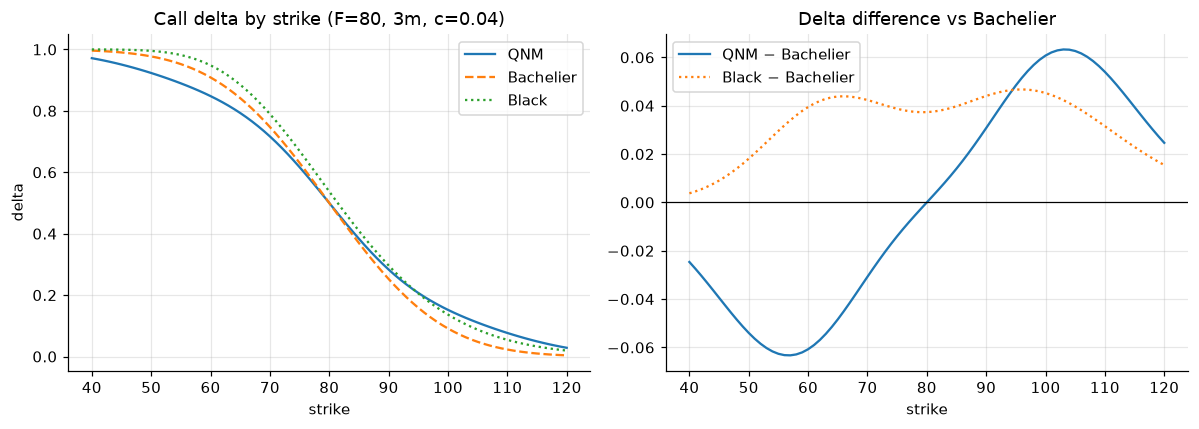

In [23]:
def qnm_delta(F, K, tau, sig, a, b, c, cp, r=RATE, disc=True):
    """Call delta (cp=+1) or put delta (cp=-1) of the QNM price."""
    m = (F - K) / (sig * np.sqrt(tau))
    v = a + b / 2 * (K + F) + c / 3 * (K**2 + K * F + F**2)
    call = (ndtr(m) + np.sqrt(tau) * npdf(m) * (b / 2 + c * (K + 2 * F) / 3)
            - (F - K) / (sig**2 * np.sqrt(tau)) * npdf(m) * (v + c / 6 * sig**2 * tau))
    d = np.where(cp > 0, call, call - 1)
    return d * np.exp(-r * tau) if disc else d


bump = 0.01
num = (qnm_price(F_ + bump, Kgrid, tau_, sig_, a_, b_, c_, 1, r=0) - qnm_price(F_ - bump, Kgrid, tau_, sig_, a_, b_, c_, 1, r=0)) / (2 * bump)
dq = qnm_delta(F_, Kgrid, tau_, sig_, a_, b_, c_, 1, r=0)
print(f"max |analytic − numeric| delta: {np.abs(dq - num).max():.2e}")

d_bch = ndtr((F_ - Kgrid) / (sig_ * np.sqrt(tau_)))
sb = sig_ / F_
d_blk = ndtr((np.log(F_ / Kgrid) + 0.5 * sb**2 * tau_) / (sb * np.sqrt(tau_)))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(Kgrid, dq, label="QNM"); ax[0].plot(Kgrid, d_bch, "--", label="Bachelier"); ax[0].plot(Kgrid, d_blk, ":", label="Black")
ax[0].set(title="Call delta by strike (F=80, 3m, c=0.04)", xlabel="strike", ylabel="delta"); ax[0].legend()
ax[1].plot(Kgrid, dq - d_bch, label="QNM − Bachelier"); ax[1].plot(Kgrid, d_blk - d_bch, ":", label="Black − Bachelier")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set(title="Delta difference vs Bachelier", xlabel="strike"); ax[1].legend()
plt.tight_layout(); plt.show()

Against Bachelier, the QNM puts more delta on far OTM calls and more negative delta on far OTM puts, so it hedges both tails harder. Black shifts delta the other way (more on calls, less on puts) because of the lognormal skew.

### 10.2 · Replication test
Sell one of three instruments and delta-hedge daily with futures until expiry: a 25-delta put, a 25-delta call, or an ATM straddle. Entries are made weekly, about 60, 53, 46 and 39 calendar days before each expiry, giving four overlapping cohorts per expiry.
- **Black / Bachelier:** the vol of the exact strike, re-read each day (standard practice).
- **QNM:** the day's single calibrated parameter set.
- P&L = premium (grown at `r`) − payoff + Σ delta × futures change. The mean is the volatility risk premium; the standard deviation is the replication error (lower is better).

In [24]:
smile = {k: (g.strike.values, g.ibv.values, g.inv.values) for k, g in opt.sort_values("strike").groupby(["date", "expiry"])}
calx = cal.set_index(["date", "expiry"])


def leg_deltas(date, E, K, cp, F, tau):
    """Undiscounted deltas of one option under each model."""
    key = (date, E)
    if key not in smile or key not in calx.index:
        return {mo: np.nan for mo in MODELS}
    Ks, ib, inv = smile[key]
    sB, sN = np.interp(K, Ks, ib), np.interp(K, Ks, inv)
    d1 = (np.log(F / K) + 0.5 * sB**2 * tau) / (sB * np.sqrt(tau))
    dN = ndtr((F - K) / (sN * np.sqrt(tau)))
    p = calx.loc[key]
    dQ = qnm_delta(F, K, tau, p.sigA, p.a, p.b, p.c, 1, disc=False)
    sign = 0 if cp > 0 else -1
    return {"Black": ndtr(d1) + sign, "Bachelier": dN + sign, "QNM": float(dQ) + sign}


def run_cohort(E, entry_days=60):
    g = cal[cal.expiry == E].sort_values("date")
    g = g[g.tau * 365 <= entry_days]
    if g.empty or E not in fut_exp.index or g.iloc[0].tau * 365 < entry_days - 6:
        return []
    e0 = g.iloc[0]
    q = opt[(opt.date == e0.date) & (opt.expiry == E)]
    z = 0.6745 * e0.sigA * np.sqrt(e0.tau)
    pick_p = q[(q.cp == -1)].iloc[(q[q.cp == -1].strike - (e0.F - z)).abs().argsort()[:1]]
    pick_c = q[(q.cp == 1)].iloc[(q[q.cp == 1].strike - (e0.F + z)).abs().argsort()[:1]]
    pick_a = q.iloc[(q.strike - e0.F).abs().argsort()[:1]]
    disc0 = np.exp(-RATE * e0.tau)
    atm_K = float(pick_a.strike.iloc[0])
    atm_prem = 2 * float(pick_a.price_eur.iloc[0]) + disc0 * abs(e0.F - atm_K)
    legs = {"25Δ put": ([(float(pick_p.strike.iloc[0]), -1)], float(pick_p.price_eur.iloc[0])),
            "25Δ call": ([(float(pick_c.strike.iloc[0]), 1)], float(pick_c.price_eur.iloc[0])),
            "ATM straddle": ([(atm_K, 1), (atm_K, -1)], atm_prem)}
    F_T = fut_exp[E]
    path = g[["date", "F", "tau"]].values
    out = []
    for name, (legs_, prem) in legs.items():
        payoff = sum(max(cp * (F_T - K), 0) for K, cp in legs_)
        dl = {mo: [] for mo in MODELS}
        for date, F, tau in path:
            ds = [leg_deltas(date, E, K, cp, F, tau) for K, cp in legs_]
            for mo in MODELS:
                dl[mo].append(sum(d[mo] for d in ds))
        dF = np.diff(np.append(path[:, 1], F_T))
        base = prem * np.exp(RATE * e0.tau) - payoff
        row = {"expiry": E, "entry": entry_days, "instrument": name, "Unhedged": base}
        for mo in MODELS:
            dm = pd.Series(dl[mo]).ffill().bfill().values
            row[mo] = base + np.sum(dm * dF)
        out.append(row)
    return out


ENTRIES = (60, 53, 46, 39)
hedge = pd.DataFrame([r for E in sorted(cal.expiry.unique()) for d in ENTRIES for r in run_cohort(E, d)])
print(f"{hedge.expiry.nunique()} expiries × {hedge.entry.nunique()} entry dates × {hedge.instrument.nunique()} instruments = {len(hedge)} hedged positions")
cols_h = ["Unhedged"] + MODELS
summ = hedge.groupby("instrument")[cols_h].agg(["mean", "std"]).round(3)
summ

35 expiries × 4 entry dates × 3 instruments = 420 hedged positions


Unhedged         Black        Bachelier           QNM       
                 mean    std   mean    std      mean    std   mean    std
instrument                                                               
25Δ call      -0.4660 5.5770 0.1180 1.1640    0.0690 1.3300 0.1760 1.0550
25Δ put        0.8780 1.1890 0.1980 0.7240    0.1650 0.7830 0.2630 0.6500
ATM straddle   0.4640 7.0230 0.4520 2.2990    0.3550 2.4900 0.5880 2.1520

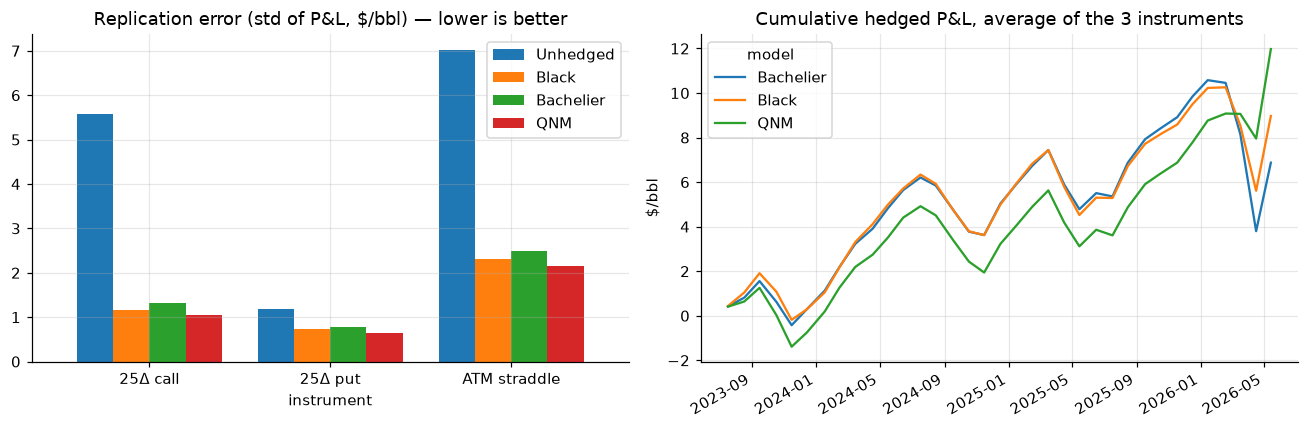

Share of expiries where QNM has the smaller absolute P&L:


,QNM beats Black,QNM beats Bachelier
instrument,,
25Δ call,0.5600,0.5300
25Δ put,0.6100,0.5500
ATM straddle,0.5900,0.5600


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sd = hedge.groupby("instrument")[cols_h].std()
sd.plot.bar(ax=axes[0], rot=0, width=0.8)
axes[0].set(title="Replication error (std of P&L, $/bbl) — lower is better")
hedge.melt(id_vars=["expiry", "instrument"], value_vars=MODELS, var_name="model", value_name="pnl") \
     .pivot_table(index="expiry", columns="model", values="pnl", aggfunc="mean").cumsum().plot(ax=axes[1])
axes[1].set(title="Cumulative hedged P&L, average of the 3 instruments", ylabel="$/bbl", xlabel="")
plt.tight_layout(); plt.show()

win = pd.DataFrame({f"QNM beats {mo}": (hedge.QNM.abs() < hedge[mo].abs()).groupby(hedge.instrument).mean() for mo in ("Black", "Bachelier")})
print("Share of expiries where QNM has the smaller absolute P&L:")
win.round(2)

### 10.3 · Is the hedging gap real?
Two checks. First, the replication error split by regime (expiries before 2026 vs 2026), because over-hedging the tails pays mainly in a trending market. Second, a paired bootstrap that resamples whole expiries (all entries and instruments of an expiry move together) and reports the ratio of QNM to Black and Bachelier replication error with a 90% interval. A ratio below 1 means the QNM hedges better.

In [26]:
hedge["regime"] = np.where(pd.to_datetime(hedge.expiry).dt.year >= 2026, "2026", "2023–2025")
by_reg = hedge.groupby(["instrument", "regime"])[MODELS].std().round(3)
by_reg["n"] = hedge.groupby(["instrument", "regime"]).size()
display(by_reg)


def ratio_ci(df, num, den, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    exp = df.expiry.unique(); groups = {e: df[df.expiry == e] for e in exp}
    out = []
    for _ in range(n):
        s = pd.concat([groups[e] for e in rng.choice(exp, len(exp), replace=True)])
        out.append(s[num].std() / s[den].std())
    return df[num].std() / df[den].std(), *np.percentile(out, [5, 95])


rows = {}
for inst, d in list(hedge.groupby("instrument")) + [("All instruments", hedge)]:
    for ref in ("Black", "Bachelier"):
        for reg, dd in [("all", d), ("2023–2025", d[d.regime == "2023–2025"]), ("2026", d[d.regime == "2026"])]:
            if dd.expiry.nunique() >= 4:
                r, lo, hi = ratio_ci(dd, "QNM", ref)
                rows[(inst, ref, reg)] = {"QNM ÷ ref": r, "CI low": lo, "CI high": hi, "expiries": dd.expiry.nunique()}
ci = pd.DataFrame(rows).T
ci.index.names = ["instrument", "vs", "regime"]
ci.style.format({"QNM ÷ ref": "{:.2f}", "CI low": "{:.2f}", "CI high": "{:.2f}", "expiries": "{:.0f}"})

Black  Bachelier    QNM    n
instrument   regime                                 
25Δ call     2023–2025 0.7030     0.6700 0.7120  120
             2026      2.6110     3.1490 2.0620   20
25Δ put      2023–2025 0.6600     0.6540 0.6540  120
             2026      0.8630     1.0660 0.6150   20
ATM straddle 2023–2025 1.6680     1.6140 1.6310  120
             2026      4.5760     5.2220 4.0290   20

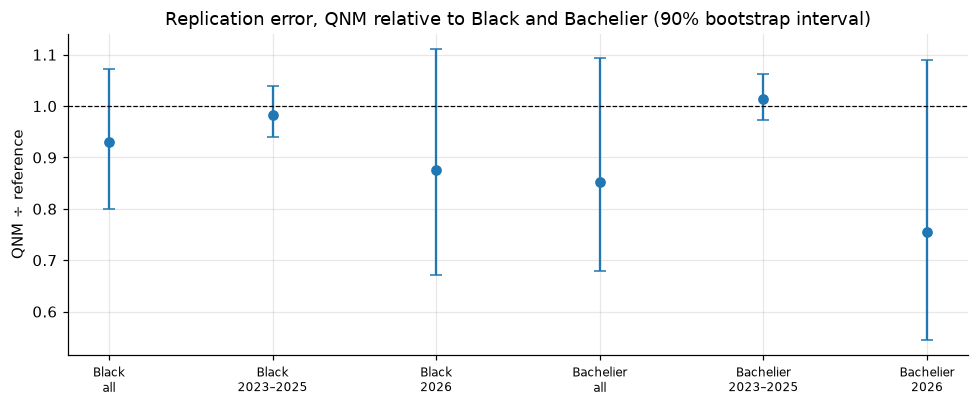

In [27]:
fig, ax = plt.subplots(figsize=(9, 3.8))
plot_ci = ci.xs("All instruments", level="instrument").reset_index()
labels = [f"{v}\n{r}" for v, r in zip(plot_ci.vs, plot_ci.regime)]
y = plot_ci["QNM ÷ ref"].astype(float)
lo, hi = plot_ci["CI low"].astype(float), plot_ci["CI high"].astype(float)
ax.errorbar(range(len(y)), y, yerr=[np.maximum(y - lo, 0), np.maximum(hi - y, 0)], fmt="o", capsize=4)
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xticks(range(len(y)), labels, fontsize=8)
ax.set(title="Replication error, QNM relative to Black and Bachelier (90% bootstrap interval)", ylabel="QNM ÷ reference")
plt.tight_layout(); plt.show()

All three delta rules cut the P&L spread sharply against no hedge. Between them, the difference is a regime effect:
- **2023–2025 (30 expiries):** no difference. The QNM-to-Black ratio is 0.98 (90% interval 0.94–1.04) and QNM-to-Bachelier 1.01 (0.97–1.06).
- **2026 (5 expiries):** the QNM error is 13–25% lower, but the intervals include 1 except for the 25-delta put against Bachelier (0.58, interval 0.46–0.98).

The QNM delta over-hedges both tails, which pays during a strong trend and costs nothing measurable otherwise. Over the full sample the ratio is 0.93 against Black (0.80–1.07): no statistically reliable hedging advantage.

## Conclusions

**Where the model is strong.** One parameter set per day and expiry reprices the whole 10-delta-to-10-delta range of WTI options to 1.2–1.5¢ in ordinary markets and 8.7¢ in the 2026 spike, 8 to 14 times tighter than a single Black or Bachelier vol. The closed form is accurate inside that range, and its parameters map onto the three quoted instruments: straddle, risk reversal and strangle.

**Interpreting the parameters.** Use level, slope and curvature at the futures price. The vertex form `(A, F0)` is algebraically tied together and unstable whenever curvature is small.

**Limits.**
- The parameters go stale within days; refit daily.
- The closed form under-prices the far wings (beyond 10-delta) by up to 60% at three months, so tail-sensitive payoffs need a numerical solution or a wider calibration.
- Normal vol is the better single-vol base in ordinary markets, but a strong call-skew regime (2026) reverses that.
- The QNM delta does not hedge better in ordinary markets; its 2026 gain is a trend effect and not statistically reliable.
- The digital value is a consistent price, not a forecast.
- Three years and four expiries per day: the maturity and hedging results are not statistically strong.

**Next steps.**
- Trade the residuals: z-score each strike's fit error and test mean reversion as a relative-value signal.
- Fit level, slope and curvature as smooth functions of maturity across the whole surface.
- Extend the pipeline to `HO`, `RB`, `NG` and Treasury options, where normal-vol quoting is standard.

In [28]:
key = pd.DataFrame({
    "in-sample": ev[(ev.h == 0) & (ev.m == 3)][MODELS].pow(2).mean().pow(0.5),
    "T+1": ev[(ev.h == 1) & (ev.m == 3)][MODELS].pow(2).mean().pow(0.5),
    "T+5": ev[(ev.h == 5) & (ev.m == 3)][MODELS].pow(2).mean().pow(0.5),
}).mul(100).round(1)
print("m3 RMSE (cents / bbl)")
key

m3 RMSE (cents / bbl)


,in-sample,T+1,T+5
Black,33.1000,41.3000,70.0000
Bachelier,58.5000,67.7000,95.2000
QNM,4.2000,18.2000,46.0000
